## Python Data fitting with various functions - HW 12
Due Monday Dec 1, 2025



Dowload the data "miniDR17.fits" from the TCU Online Week 14:<br>
<i>NOTE: it is a large-ish file and may take a while.</i>

**However, this is a small version of the full science data file (4 GB) which can be found at:**<br>
https://data.sdss.org/sas/dr17/apogee/spectro/aspcap/dr17/synspec_rev1/allStar-dr17-synspec_rev1.fits


My example below will show how to remove Identified bad data, 
however data that are just bad in one quantity may remain

_Use masking to remove any remaining bad values (typically 9999 or -9999 in this file_ , <b>but check!!!! If you are not sure, ask!!!</b>). 

In [1]:
from matplotlib import pyplot as plt
import numpy as np
from astropy.io import fits 
import scipy.optimize as opt

# POTENTIAL FITTING FUNCTIONS
def linear(x,m,b):
    return m*x+b

def poly2(x,a,b,c):
    return a*(x**2)+(b*x)+c

def poly3(x,a,b,c,d):
    return (a*(x**3))+(b*(x**2))+(c*x)+d

def cosfit (x,a,b,c,d):
    return a*np.cos(b*x + c) + d

def exponential(x,a,b,c,d):
    return a*np.exp(b*x + c) + d


# Monte Carlo-version of 2 parameter Curve Fit that can use BOTH x and Y errors
def mcFit2(func, x, y, x_err=0.1, y_err=0.1, p0=[0,0]):
    slope = list()
    y_ints = list()
    iters = 500 
    for i in range(iters):
        # remember random normal distribution (Gaussian)
        weightsx = np.random.randn(len(y))
        weightsy = np.random.randn(len(y))
        y_adj = y + y_err*weightsy
        x_adj = x + x_err*weightsx 
        popt, pcov = opt.curve_fit(func, x_adj, y_adj, p0=p0)
        slope.append(popt[0])
        y_ints.append(popt[1])
    return (np.median(slope),np.median(y_ints))


# Monte Carlo-version of 3 parameter Curve Fit that can use BOTH x and Y errors
def mcFit3(func, x, y, x_err=0.1, y_err=0.1,p0=[1,1,1]):
    paramA = list()
    paramB = list()
    paramC = list()
    iters = 500 
    for i in range(iters):
        # remember random normal distribution (Gaussian)
        weightsx = np.random.randn(len(y))
        weightsy = np.random.randn(len(y))
        y_adj = y + y_err*weightsy
        x_adj = x + x_err*weightsx 
        popt, pcov = opt.curve_fit(func, x_adj, y_adj, p0=p0)
        paramA.append(popt[0])
        paramB.append(popt[1])
        paramC.append(popt[2])
    return (np.median(paramA),np.median(paramB),np.median(paramC))

# Monte Carlo-version of 4 parameter Curve Fit that can use BOTH x and Y errors
def mcFit4(func, x, y, x_err=0.1, y_err=0.1, p0=[1,1,1,1]):
    paramA = list()
    paramB = list()
    paramC = list()
    paramD = list()
    iters = 500 
    for i in range(iters):
        # remember random normal distribution (Gaussian)
        weightsx = np.random.randn(len(y))
        weightsy = np.random.randn(len(y))
        y_adj = y + y_err*weightsy
        x_adj = x + x_err*weightsx 
        popt, pcov = opt.curve_fit(func, x_adj, y_adj, p0=p0)
        paramA.append(popt[0])
        paramB.append(popt[1])
        paramC.append(popt[2])
        paramD.append(popt[3])
    return (np.median(paramA),np.median(paramB),np.median(paramC),np.median(paramD))


In [2]:
# READ IN FITS FILES
star_hdus = fits.open('miniDR17.fits')
star = star_hdus[1].data
print(star_hdus[1].columns)
star_hdus.close()

ColDefs(
    name = 'APOGEE_ID'; format = '30A'
    name = 'RA'; format = 'D'
    name = 'DEC'; format = 'D'
    name = 'GLON'; format = 'D'
    name = 'GLAT'; format = 'D'
    name = 'TEFF'; format = 'E'
    name = 'TEFF_ERR'; format = 'E'
    name = 'LOGG'; format = 'E'
    name = 'LOGG_ERR'; format = 'E'
    name = 'J'; format = 'E'
    name = 'J_ERR'; format = 'E'
    name = 'K'; format = 'E'
    name = 'K_ERR'; format = 'E'
    name = 'SNR'; format = 'E'
    name = 'VHELIO_AVG'; format = 'E'
    name = 'VERR'; format = 'E'
    name = 'FE_H'; format = 'E'
    name = 'FE_H_ERR'; format = 'E'
    name = 'O_FE'; format = 'E'
    name = 'O_FE_ERR'; format = 'E'
    name = 'NI_FE'; format = 'E'
    name = 'NI_FE_ERR'; format = 'E'
    name = 'NVISITS'; format = 'J'
    name = 'VSCATTER'; format = 'E'
    name = 'ASPCAPFLAG'; format = 'K'
    name = 'STARFLAG'; format = 'K'
    name = 'EXTRATARG'; format = 'J'
    name = 'GAIA_PARALLAX'; format = 'E'
    name = 'GAIA_PARALLAX_ERROR'; for

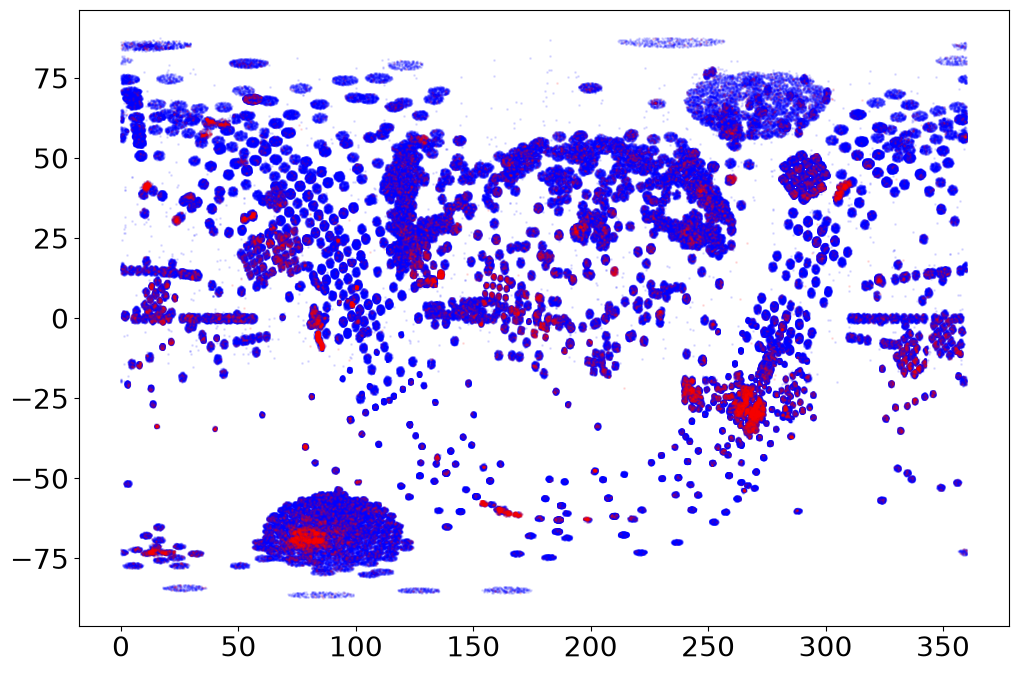

In [3]:
# TWO BITWISE FLAGS FOR BAD DATA - THESE REMOVE IDENTIFIED BAD DATA            
badbits = 2**23        # aspcapstar flag - Chemistry
suspectbits = 2**16    # star flag - Stellar parameters

# Make a Boolena Mask to remove bad data
gd = (np.bitwise_and(star['aspcapflag'], badbits) == 0) &\
     (np.bitwise_and(star['starflag'], suspectbits) == 0) 
bd = (np.bitwise_and(star['aspcapflag'], badbits) != 0) |\
     (np.bitwise_and(star['starflag'], suspectbits) != 0) 

good = np.where(gd)[0]
bad = np.where(bd)[0]

# PLOT TO VERIFY FITS FILE READ IN & BAD MASK DATA
fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111)
ax.scatter(star['RA'][good],star['DEC'][good],s=1,c='b',alpha=0.1)
ax.scatter(star['RA'][bad],star['DEC'][bad],s=1,c='r',alpha=0.1)


ax.xaxis.set_tick_params(labelsize=20)
ax.yaxis.set_tick_params(labelsize=20)
plt.show()

LINEAR: -0.074, 16.223
POLY2: 0.005, -1.877, 130.634
COSFIT: 72.947, 0.018, -0.452, -5.700


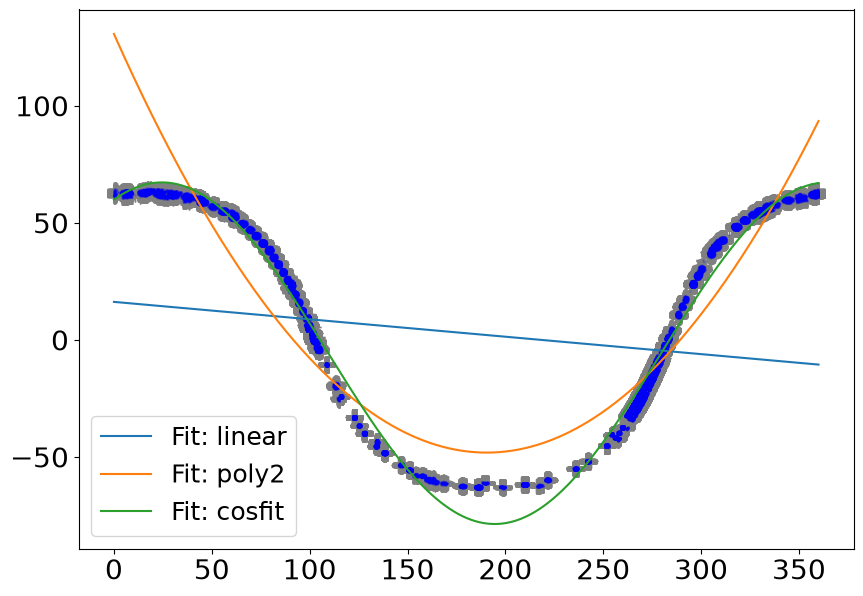

In [4]:
# EXAMPLE FIT - DR. FRINCHABOY
# --------------------------------------------
# First use Linear, Polnomial, and Cosine Fits
# Select stars only with with  −2 < GLAT < 2   
# 
# I FIT RA & DEC data versus LINEAR, POLY2, AND COSFIT in this example.  
#
# TWO BITWISE FLAGS TO REMOVE FOR OBVIOUSLY BAD DATA             
badbits = 2**23        # aspcapstar flag - Chemistry
suspectbits = 2**16    # star flag - Stellar parameters

#=================================================================================
# Make a Boolena Mask to remove bad data - AND ANY OTHER NEEDED CUTS 
# (e.g., −2 < GLAT < 2 ) or other 'bad' data not removed by the flags.
ct1 = (np.bitwise_and(star['aspcapflag'], badbits) == 0) & \
     (np.bitwise_and(star['starflag'], suspectbits) == 0) & \
     (star['GLAT'] < 2) &\
     (star['GLAT'] > -2) 
cut1 = np.where(ct1)[0]

#=================================================================================
## LINEAR FIT (2 parameter)
slope, intercept = mcFit2(linear, star['RA'][cut1], star['DEC'][cut1], 0.001, \
                          0.001, p0=[0,0])
print(f'LINEAR: {slope:.3f}, {intercept:.3f}')

#=================================================================================
## POLY2 FIT (3 parameter)
polyA, polyB, polyC,  = mcFit3(poly2, star['RA'][cut1], star['DEC'][cut1], 0.001, \
                         0.001,p0=[600,1,1])
print(f'POLY2: {polyA:.3f}, {polyB:.3f}, {polyC:.3f}')

#=================================================================================
## COS FIT (4 parameter)
cfA, cfB, cfC, cfD = mcFit4(cosfit, star['RA'][cut1], star['DEC'][cut1], 0.001, \
                            0.001,p0=[60,0.02,0,0])
print(f'COSFIT: {cfA:.3f}, {cfB:.3f}, {cfC:.3f}, {cfD:.3f}')
#=================================================================================



# PLOT TO VERIFY FITS FILE READ IN & BAD MASK DATA
fig1 = plt.figure(figsize=(10,7))
ax1 = fig1.add_subplot(111)
ax1.xaxis.set_tick_params(labelsize=20)
ax1.yaxis.set_tick_params(labelsize=20)

# PLOT DATA AND ERROR BARS
ax1.scatter(star['RA'][cut1],star['DEC'][cut1],s=1,c='b',alpha=0.1)
ax1.errorbar((star['RA'][cut1]),star['DEC'][cut1], xerr=(0.001),
             yerr=(0.001), ecolor='grey',fmt='none', capsize=5, zorder=0)


#=================================================================================
# PLOT DATA FITS FROM ABOVE
x_plot = np.linspace(0,360,1000) # X-PLOTING FOR FITS

#=================================================================================
#linear fit
ax1.plot(x_plot,linear(x_plot, slope, intercept), label='Fit: linear')
#poly2 fit
ax1.plot(x_plot,poly2(x_plot, polyA, polyB, polyC), label='Fit: poly2')
#cosfit
ax1.plot(x_plot,cosfit(x_plot, cfA, cfB, cfC, cfD), label='Fit: cosfit')

plt.legend(loc='best', fontsize=18)
plt.show()

# Homework #12

**REMINDER:** *All coding assignment will be turned in as .ipynb files, to the same PHYS_X0223 repository on GitHub.*   
*They should be turned in with the following naming:*
    
    Lastname_Firstinitial_24_HW12a.ipynb

## DATA FIT 1

Fit a linear, polynomial (poly2), and a polynomial (poly3) functions and to the following selections of the data:
1. Select stars only with with $ GLAT > 20$ <br>
   __Fit Fe\_H,  (Fe\_H\_ERR)  vs.  O\_FE (O\_FE\_ERR)__<br>

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)


DATA FIT 1: GLAT > 20
Number of valid stars: 232605
Linear best-fit parameters: [np.float64(-1.045113), np.float64(-0.12104)]
Poly2 best-fit parameters: [np.float64(-1.036395), np.float64(-0.7375), np.float64(-0.111525)]
Poly3 best-fit parameters: [np.float64(0.292916), np.float64(-1.11513), np.float64(-0.790798), np.float64(-0.106727)]


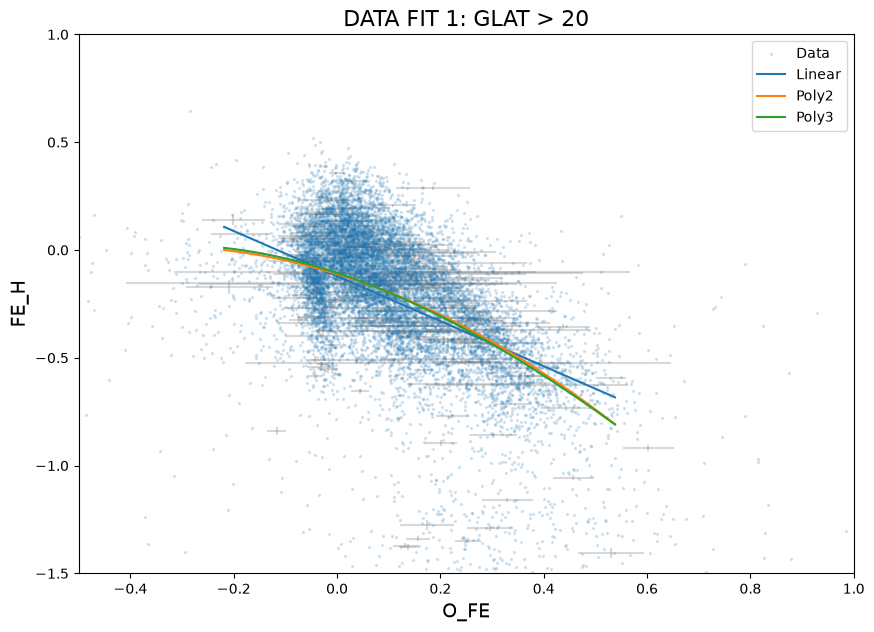

In [5]:
np.random.seed(42)

def run_hw_fit(title, selection, x, y, xerr, yerr,
               models, xlabel, ylabel):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xerr = np.broadcast_to(xerr, x.shape).astype(float)
    yerr = np.broadcast_to(yerr, y.shape).astype(float)

    
    valid = (
        np.asarray(selection, dtype=bool) &
        np.isfinite(x) & np.isfinite(y) &
        np.isfinite(xerr) & np.isfinite(yerr) &
        (np.abs(x) < 9999) &
        (np.abs(y) < 9999) &
        (xerr >= 0) & (xerr < 9999) &
        (yerr >= 0) & (yerr < 9999)
    )

    x = x[valid]
    y = y[valid]
    xerr = xerr[valid]
    yerr = yerr[valid]

    print('\n' + title)
    print('Number of valid stars:', len(x))

    if len(x) < 4:
        print('Not enough valid data to perform the fits.')
        return

    
    nplot = min(12000, len(x))
    plot_idx = np.random.choice(len(x), nplot, replace=False)

    fig, ax = plt.subplots(figsize=(10, 7))

    ax.scatter(x[plot_idx], y[plot_idx],
               s=2, alpha=0.15, label='Data')

    # Plot a smaller selection of error bars
    nerr = min(250, len(x))
    err_idx = np.random.choice(len(x), nerr, replace=False)

    ax.errorbar(
        x[err_idx], y[err_idx],
        xerr=xerr[err_idx],
        yerr=yerr[err_idx],
        fmt='none',
        ecolor='grey',
        alpha=0.3,
        zorder=0
    )


    x_plot = np.linspace(
        np.percentile(x, 1),
        np.percentile(x, 99),
        1000
    )

    for name, func, p0, nparams in models:

        try:
            if nparams == 2:
                params = mcFit2(
                    func, x, y, xerr, yerr, p0=p0
                )

            elif nparams == 3:
                params = mcFit3(
                    func, x, y, xerr, yerr, p0=p0
                )

            elif nparams == 4:
                params = mcFit4(
                    func, x, y, xerr, yerr, p0=p0
                )

            print(name, 'best-fit parameters:',
                  [round(p, 6) for p in params])

            ax.plot(
                x_plot,
                func(x_plot, *params),
                label=name
            )

        except (RuntimeError, ValueError,
                FloatingPointError) as error:

            print(name, 'fit did not converge:', error)

    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_title(title, fontsize=16)
    plt.xlim(-0.5,1.00)
    plt.ylim(-1.5,1.00)
    ax.legend()
    plt.show()
    
    

badbits = 2**23
suspectbits = 2**16

good_flags = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0)
)



cut1 = good_flags & (star['GLAT'] > 20)

models1 = [
    ('Linear', linear, [0, 0], 2),
    ('Poly2', poly2, [0, 0, 0], 3),
    ('Poly3', poly3, [0, 0, 0, 0], 4)
]

run_hw_fit(
    'DATA FIT 1: GLAT > 20',
    cut1,
    star['O_FE'],
    star['FE_H'],
    star['O_FE_ERR'],
    star['FE_H_ERR'],
    models1,
    'O_FE',
    'FE_H'
)


## DATA FIT 2

Fit a linear, polynomial (poly2), and a polynomial (poly3) functions and to the following selections of the data:
2. Select stars only with with $-1< GLAT < 1$ <br>
   __Fit Fe\_H,  (Fe\_H\_ERR)  vs.  O\_FE (O\_FE\_ERR)__<br>

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)

DATA FIT 2
Number of valid stars: 38495

LINEAR FIT
Slope, intercept: [-1.04982882 -0.05092675]
R-squared: 0.1633059639019917

POLY2 FIT
a, b, c: [-0.82551552 -0.90060321 -0.04615131]
R-squared: 0.19970667651308072

POLY3 FIT
a, b, c, d: [ 1.16421858 -1.38214457 -1.04500499 -0.03230821]
R-squared: 0.22846888402062715


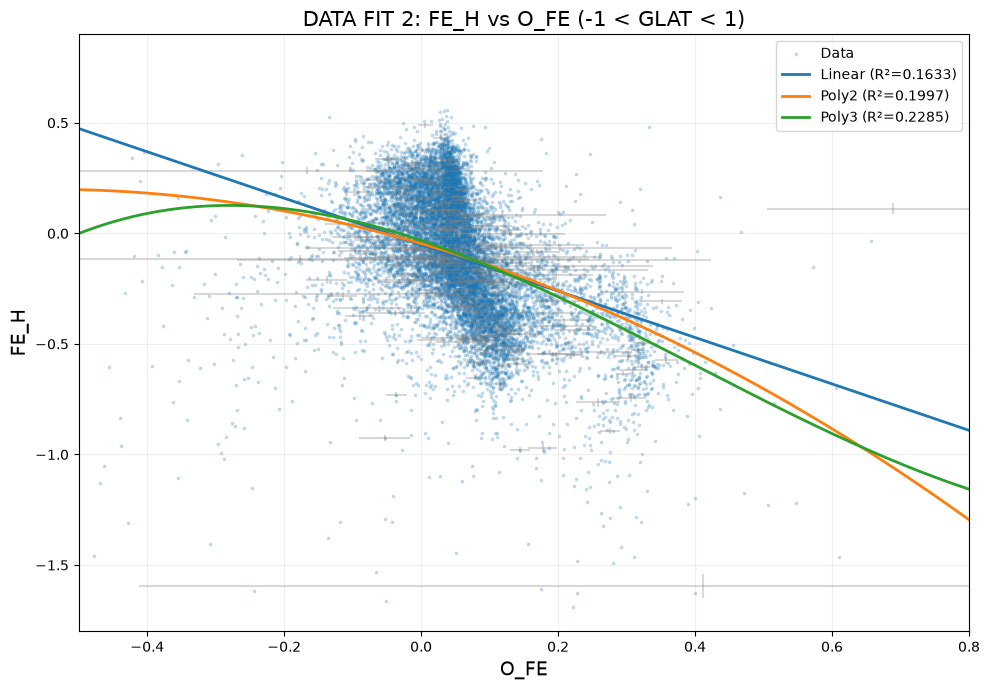

In [20]:

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

# Load data if it has not already been loaded
if 'star' not in globals():
    with fits.open('miniDR17.fits', memmap=True) as hdul:
        star = hdul[1].data.copy()


badbits = 2**23
suspectbits = 2**16

gd = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0)
)



x_all = np.asarray(star['O_FE'], dtype=float)
y_all = np.asarray(star['FE_H'], dtype=float)

xe_all = np.asarray(star['O_FE_ERR'], dtype=float)
ye_all = np.asarray(star['FE_H_ERR'], dtype=float)

glat = np.asarray(star['GLAT'], dtype=float)


cut2 = (
    gd &
    (glat > -1) &
    (glat < 1) &
    np.isfinite(x_all) &
    np.isfinite(y_all) &
    np.isfinite(xe_all) &
    np.isfinite(ye_all) &
    (np.abs(x_all) < 9999) &
    (np.abs(y_all) < 9999) &
    (xe_all >= 0) & (xe_all < 9999) &
    (ye_all >= 0) & (ye_all < 9999)
)

x = x_all[cut2]
y = y_all[cut2]
xe = xe_all[cut2]
ye = ye_all[cut2]

print('DATA FIT 2')
print('Number of valid stars:', len(x))

if len(x) < 4:
    print('Not enough valid stars to perform the fits.')

else:

    np.random.seed(42)

    rng = np.random.default_rng(42)

    n_sample = min(10000, len(x))

    sample = rng.choice(len(x), n_sample, replace=False)

    xs = x[sample]
    ys = y[sample]
    xes = xe[sample]
    yes = ye[sample]

    linear_results = []
    poly2_results = []
    poly3_results = []

    for i in range(50):

        x_adj = xs + rng.normal(size=len(xs)) * xes
        y_adj = ys + rng.normal(size=len(ys)) * yes

        linear_results.append(np.polyfit(x_adj, y_adj, 1))
        poly2_results.append(np.polyfit(x_adj, y_adj, 2))
        poly3_results.append(np.polyfit(x_adj, y_adj, 3))

    # Median best-fit parameters
    linear_pars = np.median(linear_results, axis=0)
    poly2_pars = np.median(poly2_results, axis=0)
    poly3_pars = np.median(poly3_results, axis=0)


    def calculate_r2(actual, predicted):
        total = np.sum((actual - np.mean(actual))**2)

        if total == 0:
            return np.nan

        return 1 - np.sum((actual - predicted)**2) / total

    linear_r2 = calculate_r2(y, np.polyval(linear_pars, x))
    poly2_r2 = calculate_r2(y, np.polyval(poly2_pars, x))
    poly3_r2 = calculate_r2(y, np.polyval(poly3_pars, x))


    print('\nLINEAR FIT')
    print('Slope, intercept:', linear_pars)
    print('R-squared:', linear_r2)

    print('\nPOLY2 FIT')
    print('a, b, c:', poly2_pars)
    print('R-squared:', poly2_r2)

    print('\nPOLY3 FIT')
    print('a, b, c, d:', poly3_pars)
    print('R-squared:', poly3_r2)


    fig, ax = plt.subplots(figsize=(10, 7))

    # Plot data
    nplot = min(12000, len(x))
    plot_idx = rng.choice(len(x), nplot, replace=False)

    ax.scatter(
        x[plot_idx],
        y[plot_idx],
        s=3,
        alpha=0.2,
        label='Data'
    )

    nerr = min(250, len(x))
    err_idx = rng.choice(len(x), nerr, replace=False)

    ax.errorbar(
        x[err_idx],
        y[err_idx],
        xerr=xe[err_idx],
        yerr=ye[err_idx],
        fmt='none',
        ecolor='grey',
        alpha=0.3
    )

    x_plot = np.linspace(np.min(x), np.max(x), 1000)

    ax.plot(
        x_plot,
        np.polyval(linear_pars, x_plot),
        linewidth=2,
        label=f'Linear (R²={linear_r2:.4f})'
    )

    ax.plot(
        x_plot,
        np.polyval(poly2_pars, x_plot),
        linewidth=2,
        label=f'Poly2 (R²={poly2_r2:.4f})'
    )

    ax.plot(
        x_plot,
        np.polyval(poly3_pars, x_plot),
        linewidth=2,
        label=f'Poly3 (R²={poly3_r2:.4f})'
    )

    ax.set_xlabel('O_FE', fontsize=14)
    ax.set_ylabel('FE_H', fontsize=14)

    ax.set_title(
        'DATA FIT 2: FE_H vs O_FE (-1 < GLAT < 1)',
        fontsize=15
    )

    ax.legend()
    ax.grid(alpha=0.2)
    plt.xlim(-0.5,.8)
    plt.ylim(-1.8,0.9)

    plt.tight_layout()
    plt.show()

## DATA FIT 3

Fit a linear, polynomial (poly3), and a exponetial functions and to the following selections of the data:
3. Select stars only with with $340 < GLON < 360$ <br>
   __Fit TEFF,  (TEFF\_ERR)  vs.  LOGG (LOGG\_ERR)__<br>

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)

DATA FIT 3
Number of valid stars: 38909

LINEAR FIT
Slope and intercept: [ 376.45416522 3705.87076068]

POLY3 FIT
a, b, c, d: [-120.28764856  716.65487048 -500.61408824 3665.37068184]

EXPONENTIAL FIT
a, b, c, d: [1.19010889e+03 7.51749937e-02 1.16348638e+00 2.39506866e-06]
Successful exponential fits: 50 out of 50


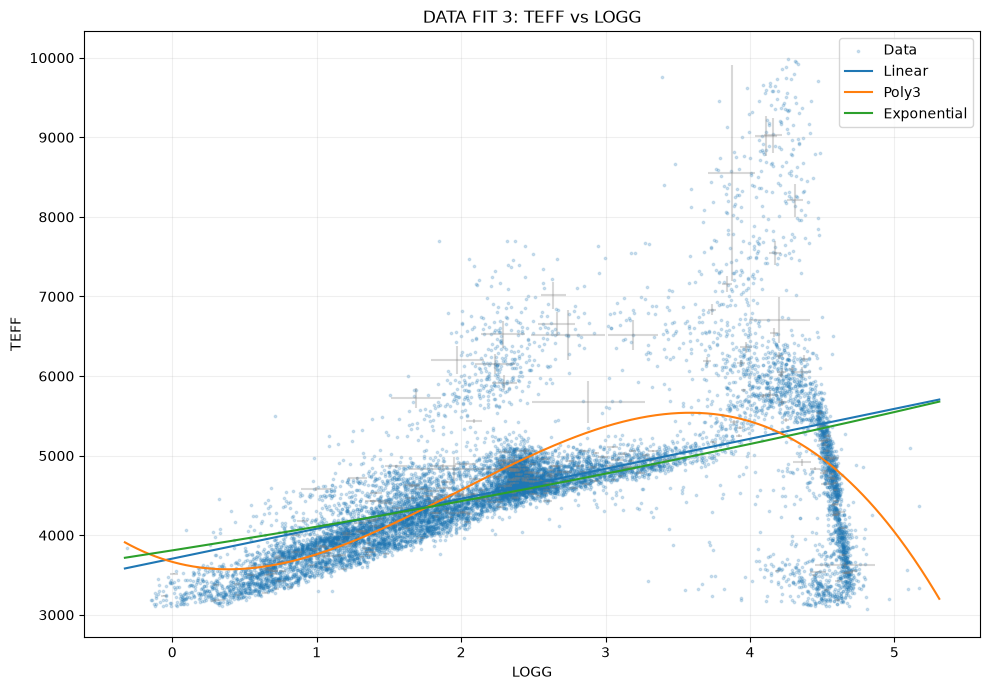

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits

if 'star' not in globals():
    with fits.open('miniDR17.fits', memmap=True) as hdul:
        star = hdul[1].data.copy()

badbits = 2**23
suspectbits = 2**16

gd = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0)
)

x_all = np.asarray(star['LOGG'], dtype=float)
y_all = np.asarray(star['TEFF'], dtype=float)
xe_all = np.asarray(star['LOGG_ERR'], dtype=float)
ye_all = np.asarray(star['TEFF_ERR'], dtype=float)
glon = np.asarray(star['GLON'], dtype=float)

cut = (
    gd & (glon > 340) & (glon < 360) &
    np.isfinite(x_all) & np.isfinite(y_all) &
    np.isfinite(xe_all) & np.isfinite(ye_all) &
    (np.abs(x_all) < 9999) & (np.abs(y_all) < 9999) &
    (xe_all >= 0) & (xe_all < 9999) &
    (ye_all >= 0) & (ye_all < 9999)
)

x = x_all[cut]
y = y_all[cut]
xe = xe_all[cut]
ye = ye_all[cut]

print('DATA FIT 3')
print('Number of valid stars:', len(x))

if len(x) < 10:
    print('Not enough valid stars for fitting.')

else:

    def exponential(x, a, b, c, d):
        return a * np.exp(np.clip(b*x + c, -100, 100)) + d

    rng = np.random.default_rng(43)

    n_sample = min(5000, len(x))
    sample = rng.choice(len(x), n_sample, replace=False)

    xs, ys = x[sample], y[sample]
    xes, yes = xe[sample], ye[sample]

    linear_results = []
    poly3_results = []
    exp_results = []

    exp_start = [1000, -0.5, 1, 4000]

    for i in range(50):

        x_adj = xs + rng.normal(size=len(xs))*xes
        y_adj = ys + rng.normal(size=len(ys))*yes

        linear_results.append(np.polyfit(x_adj, y_adj, 1))
        poly3_results.append(np.polyfit(x_adj, y_adj, 3))

        try:
            pars, covariance = curve_fit(
                exponential,
                x_adj,
                y_adj,
                p0=exp_start,
                bounds=(
                    [-100000, -10, -20, 0],
                    [100000, 10, 20, 10000]
                ),
                maxfev=30000
            )

            if np.all(np.isfinite(pars)):
                exp_results.append(pars)

        except (RuntimeError, ValueError, FloatingPointError):
            pass

    linear_pars = np.median(linear_results, axis=0)
    poly3_pars = np.median(poly3_results, axis=0)

    print('\nLINEAR FIT')
    print('Slope and intercept:', linear_pars)

    print('\nPOLY3 FIT')
    print('a, b, c, d:', poly3_pars)

    # Plot
    fig, ax = plt.subplots(figsize=(10, 7))

    plot_idx = rng.choice(
        len(x), min(12000, len(x)), replace=False
    )

    ax.scatter(
        x[plot_idx], y[plot_idx],
        s=3, alpha=0.2, label='Data'
    )

    err_idx = rng.choice(
        len(x), min(300, len(x)), replace=False
    )

    ax.errorbar(
        x[err_idx], y[err_idx],
        xerr=xe[err_idx], yerr=ye[err_idx],
        fmt='none', ecolor='grey', alpha=0.3
    )

    x_plot = np.linspace(np.min(x), np.max(x), 800)

    ax.plot(
        x_plot, np.polyval(linear_pars, x_plot),
        label='Linear'
    )

    ax.plot(
        x_plot, np.polyval(poly3_pars, x_plot),
        label='Poly3'
    )

    if len(exp_results) > 0:
        exp_pars = np.median(exp_results, axis=0)

        print('\nEXPONENTIAL FIT')
        print('a, b, c, d:', exp_pars)
        print('Successful exponential fits:', len(exp_results), 'out of 50')

        ax.plot(
            x_plot, exponential(x_plot, *exp_pars),
            label='Exponential'
        )
    else:
        print('\nExponential fit did not converge in any trial.')

    ax.set_xlabel('LOGG')
    ax.set_ylabel('TEFF')
    ax.set_title('DATA FIT 3: TEFF vs LOGG')
    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

## DATA FIT 4

Fit  a linear, a exponential, and a polynomial (poly2) functions and to the following selections of the data:
4. Select stars only with with $DEC < -50$ and $50 < RA < 120$ <br>
   __Fit TEFF,  (TEFF\_ERR)   vs.  (star['J'] - star['K']) (JK_ERR)__<br>
<br>
<b>NOTE: you will have to create a (J-K) error:</b>  JK_ERR = np.sqrt( J\_ERR^2 + K\_ERR^2 )<br> 

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)

DATA FIT 4
Number of valid stars: 54011

LINEAR FIT
Slope and intercept: [-2515.61483958  6592.95241531]

POLY2 FIT
a, b, c: [ 1300.40339688 -4634.87248471  7315.57307911]

EXPONENTIAL FIT
a, b, c, d: [ 3.18605548e+03 -1.72045526e+00  4.43495015e-01  3.14961257e+03]
Successful exponential fits: 50 out of 50


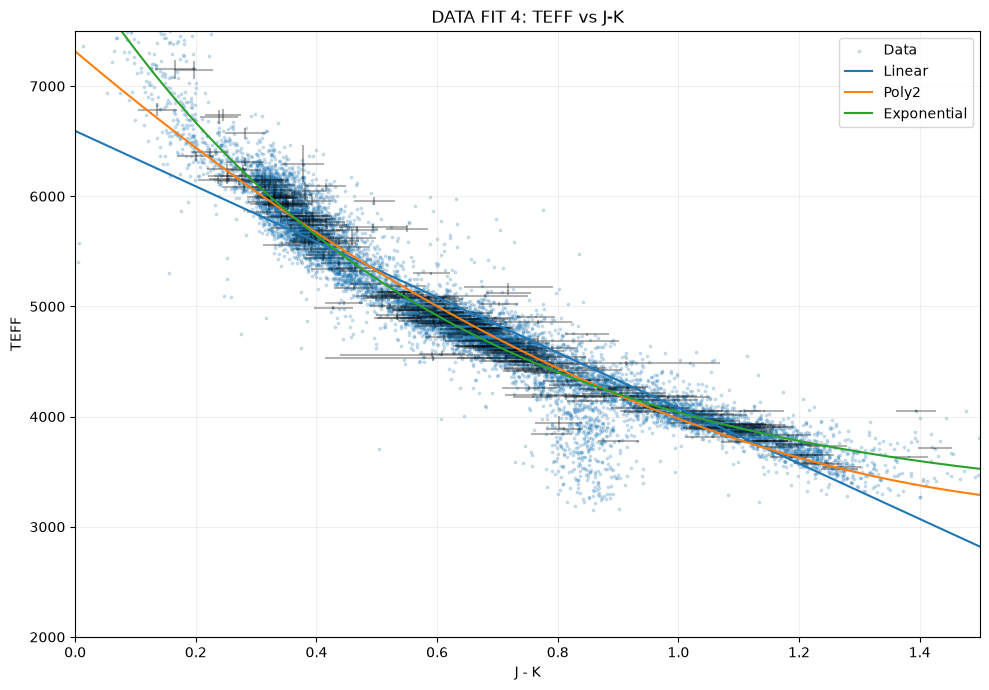

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits

if 'star' not in globals():
    with fits.open('miniDR17.fits', memmap=True) as hdul:
        star = hdul[1].data.copy()

badbits = 2**23
suspectbits = 2**16

gd = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0)
)

ra = np.asarray(star['RA'], dtype=float)
dec = np.asarray(star['DEC'], dtype=float)

j = np.asarray(star['J'], dtype=float)
k = np.asarray(star['K'], dtype=float)

teff = np.asarray(star['TEFF'], dtype=float)
teff_err = np.asarray(star['TEFF_ERR'], dtype=float)

j_err = np.asarray(star['J_ERR'], dtype=float)
k_err = np.asarray(star['K_ERR'], dtype=float)


x_all = j - k
y_all = teff

xe_all = np.sqrt(j_err**2 + k_err**2)
ye_all = teff_err

cut = (
    gd &
    (dec < -50) &
    (ra > 50) & (ra < 120) &
    np.isfinite(x_all) & np.isfinite(y_all) &
    np.isfinite(xe_all) & np.isfinite(ye_all) &
    (np.abs(x_all) < 9999) &
    (np.abs(y_all) < 9999) &
    (xe_all >= 0) & (xe_all < 9999) &
    (ye_all >= 0) & (ye_all < 9999)
)

x = x_all[cut]
y = y_all[cut]
xe = xe_all[cut]
ye = ye_all[cut]

print('DATA FIT 4')
print('Number of valid stars:', len(x))

if len(x) < 10:
    print('Not enough valid stars for fitting.')

else:

    def exponential(x, a, b, c, d):
        return a * np.exp(np.clip(b*x + c, -100, 100)) + d

    rng = np.random.default_rng(44)

    n_sample = min(5000, len(x))
    sample = rng.choice(len(x), n_sample, replace=False)

    xs, ys = x[sample], y[sample]
    xes, yes = xe[sample], ye[sample]

    linear_results = []
    exp_results = []
    poly2_results = []

    exp_start = [1000, -1, 0, 3000]

    for i in range(50):

        x_adj = xs + rng.normal(size=len(xs))*xes
        y_adj = ys + rng.normal(size=len(ys))*yes

        linear_results.append(np.polyfit(x_adj, y_adj, 1))
        poly2_results.append(np.polyfit(x_adj, y_adj, 2))

        try:
            pars, covariance = curve_fit(
                exponential,
                x_adj,
                y_adj,
                p0=exp_start,
                bounds=(
                    [-100000, -20, -20, 0],
                    [100000, 20, 20, 10000]
                ),
                maxfev=30000
            )

            if np.all(np.isfinite(pars)):
                exp_results.append(pars)

        except (RuntimeError, ValueError, FloatingPointError):
            pass

    linear_pars = np.median(linear_results, axis=0)
    poly2_pars = np.median(poly2_results, axis=0)

    print('\nLINEAR FIT')
    print('Slope and intercept:', linear_pars)

    print('\nPOLY2 FIT')
    print('a, b, c:', poly2_pars)


    fig, ax = plt.subplots(figsize=(10, 7))

    plot_idx = rng.choice(
        len(x), min(12000, len(x)), replace=False
    )

    ax.scatter(
        x[plot_idx], y[plot_idx],
        s=3, alpha=0.2, label='Data'
    )

    err_idx = rng.choice(
        len(x), min(300, len(x)), replace=False
    )

    ax.errorbar(
        x[err_idx], y[err_idx],
        xerr=xe[err_idx], yerr=ye[err_idx],
        fmt='none', ecolor='black', alpha=0.3
    )

    x_plot = np.linspace(np.min(x), np.max(x), 800)

    ax.plot(
        x_plot, np.polyval(linear_pars, x_plot),
        label='Linear'
    )

    ax.plot(
        x_plot, np.polyval(poly2_pars, x_plot),
        label='Poly2'
    )

    if len(exp_results) > 0:
        exp_pars = np.median(exp_results, axis=0)

        print('\nEXPONENTIAL FIT')
        print('a, b, c, d:', exp_pars)
        print('Successful exponential fits:', len(exp_results), 'out of 50')

        ax.plot(
            x_plot, exponential(x_plot, *exp_pars),
            label='Exponential'
        )
    else:
        print('\nExponential fit did not converge in any trial.')

    ax.set_xlabel('J - K')
    ax.set_ylabel('TEFF')
    ax.set_title('DATA FIT 4: TEFF vs J-K')
    ax.legend()
    ax.grid(alpha=0.2)
    plt.ylim(2000,7500)
    plt.xlim(0,1.5)
    plt.tight_layout()
    plt.show()


## DATA FIT 5

Fit  a linear, a polynomial (poly3), and a cosfit functions and to the following selections of the data:
5. Select stars only with with $-10< GLAT < 10$<br>
   __Fit GLON (0.0001) vs.  VHEILO\_AVG (VERR)__<br>
<br>

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)

DATA FIT 5
Number of valid stars: 196656

LINEAR FIT
Slope and intercept: [-2.36500887e-03 -3.10643157e+00]

POLY3 FIT
a, b, c, d: [-2.78752989e-05  1.43722673e-02 -1.79265633e+00  2.88469319e+01]

Successful cosine fits: 50 out of 50

COSINE FIT
a, b, c, d: [5.01247743e+01 2.26272674e-02 8.72779953e-01 1.40748854e+00]


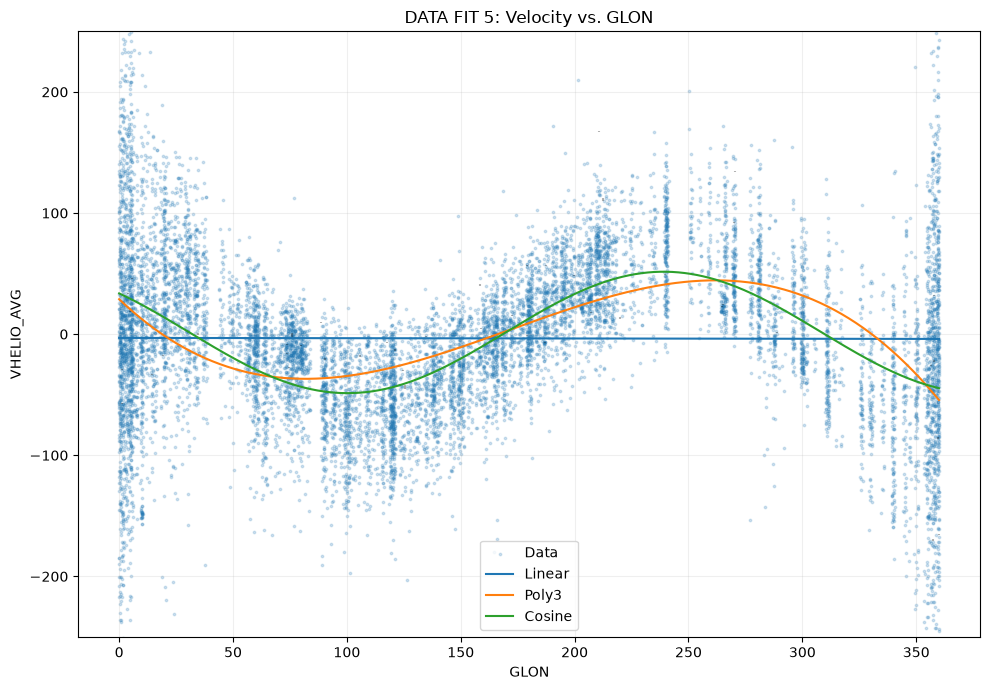

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from astropy.io import fits

if 'star' not in globals():
    with fits.open('miniDR17.fits', memmap=True) as hdul:
        star = hdul[1].data.copy()

badbits = 2**23
suspectbits = 2**16

gd = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0)
)


glat = np.asarray(star['GLAT'], dtype=float)
glon = np.asarray(star['GLON'], dtype=float)


column_names = list(star.dtype.names)
name_lookup = {name.upper(): name for name in column_names}

if 'VHEILO_AVG' in name_lookup:
    velocity_name = name_lookup['VHEILO_AVG']
elif 'VHELIO_AVG' in name_lookup:
    velocity_name = name_lookup['VHELIO_AVG']
else:
    raise KeyError('Could not find VHEILO_AVG or VHELIO_AVG.')

velocity = np.asarray(star[velocity_name], dtype=float)
velocity_err = np.asarray(star['VERR'], dtype=float)


glon_err = np.full(len(glon), 0.0001)

cut = (
    gd &
    (glat > -10) & (glat < 10) &
    np.isfinite(glon) &
    np.isfinite(velocity) &
    np.isfinite(glon_err) &
    np.isfinite(velocity_err) &
    (np.abs(glon) < 9999) &
    (np.abs(velocity) < 9999) &
    (velocity_err >= 0) &
    (velocity_err < 9999)
)

x = glon[cut]
y = velocity[cut]
xe = glon_err[cut]
ye = velocity_err[cut]

print('DATA FIT 5')
print('Number of valid stars:', len(x))

if len(x) < 10:
    print('Not enough valid stars for fitting.')

else:


    def cosfit(x, a, b, c, d):
        return a * np.cos(b*x + c) + d



    rng = np.random.default_rng(55)

    n_sample = min(5000, len(x))
    sample = rng.choice(len(x), n_sample, replace=False)

    xs, ys = x[sample], y[sample]
    xes, yes = xe[sample], ye[sample]

    linear_results = []
    poly3_results = []
    cos_results = []

    cos_start = [60, 0.02, 0, np.mean(ys)]

    for i in range(50):

        x_adj = xs + rng.normal(size=len(xs))*xes
        y_adj = ys + rng.normal(size=len(ys))*yes

        linear_results.append(
            np.polyfit(x_adj, y_adj, 1)
        )

        poly3_results.append(
            np.polyfit(x_adj, y_adj, 3)
        )

        try:
            pars, covariance = curve_fit(
                cosfit,
                x_adj,
                y_adj,
                p0=cos_start,
                maxfev=30000
            )

            if np.all(np.isfinite(pars)):
                cos_results.append(pars)

        except (RuntimeError, ValueError, FloatingPointError):
            pass

    linear_pars = np.median(linear_results, axis=0)
    poly3_pars = np.median(poly3_results, axis=0)


    print('\nLINEAR FIT')
    print('Slope and intercept:', linear_pars)

    print('\nPOLY3 FIT')
    print('a, b, c, d:', poly3_pars)

    print('\nSuccessful cosine fits:', len(cos_results), 'out of 50')

    if len(cos_results) > 0:
        cos_pars = np.median(cos_results, axis=0)

        print('\nCOSINE FIT')
        print('a, b, c, d:', cos_pars)



    fig, ax = plt.subplots(figsize=(10, 7))

    plot_idx = rng.choice(
        len(x), min(12000, len(x)), replace=False
    )

    ax.scatter(
        x[plot_idx],
        y[plot_idx],
        s=3,
        alpha=0.2,
        label='Data'
    )

    err_idx = rng.choice(
        len(x), min(300, len(x)), replace=False
    )

    ax.errorbar(
        x[err_idx],
        y[err_idx],
        xerr=xe[err_idx],
        yerr=ye[err_idx],
        fmt='none',
        ecolor='black',
        alpha=0.3
    )

    x_plot = np.linspace(np.min(x), np.max(x), 800)


    ax.plot(
        x_plot,
        np.polyval(linear_pars, x_plot),
        label='Linear'
    )


    ax.plot(
        x_plot,
        np.polyval(poly3_pars, x_plot),
        label='Poly3'
    )


    if len(cos_results) > 0:
        ax.plot(
            x_plot,
            cosfit(x_plot, *cos_pars),
            label='Cosine'
        )

    ax.set_xlabel('GLON')
    ax.set_ylabel(velocity_name)
    ax.set_title('DATA FIT 5: Velocity vs. GLON')
    ax.legend()
    ax.grid(alpha=0.2)
    plt.ylim(-250,250)
    plt.tight_layout()
    plt.show()

## DATA FIT 6

Fit  a linear and a polynomial (poly2 AND poly3) functions and to the following selections of the data:
7. __Fit Fe\_H,  (Fe\_H\_ERR)  vs.  NI\_FE (NI\_FE\_ERR)__<br>
<br>

For this fit of the above selection:

1. What are the best-fit values of the parameters? 
2. Which fucntion fits the data best?
3. Is there a second population? (Can you fit outliers with a reasonable linear trend?)

DATA FIT 6
Number of selected stars: 648123
LINEAR: 0.532, -0.123
POLY2: -0.281, 0.484, -0.121
POLY3: -0.868, -1.079, 0.566, -0.120


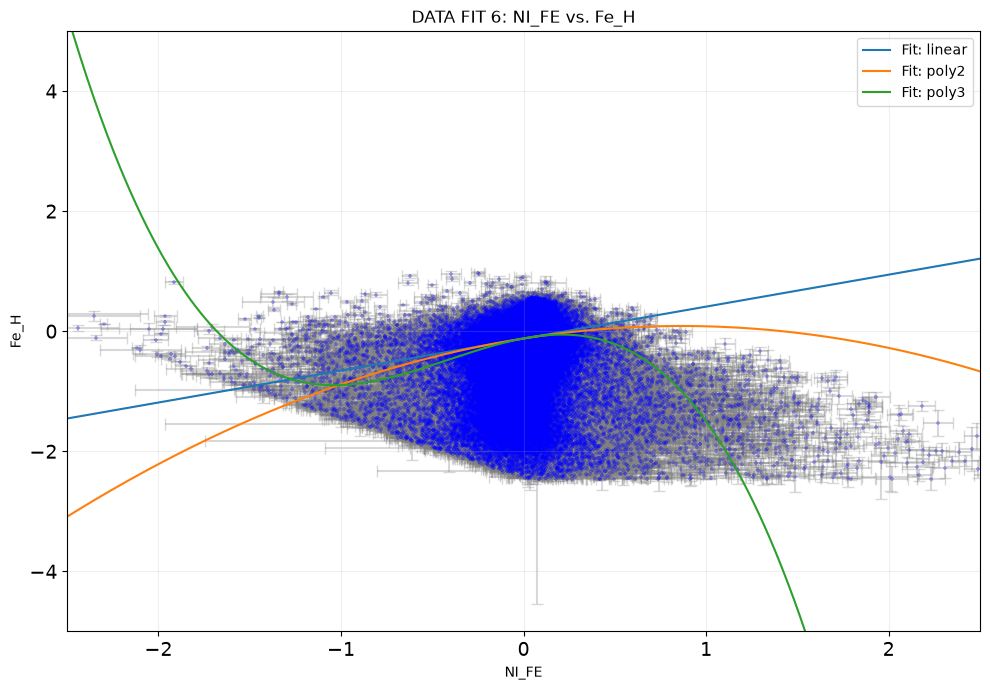

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

if 'star' not in globals():
    with fits.open('miniDR17.fits', memmap=True) as hdul:
        star = hdul[1].data.copy()

def linear(x, m, b):
    return m*x + b

def poly2(x, a, b, c):
    return a*x**2 + b*x + c

def poly3(x, a, b, c, d):
    return a*x**3 + b*x**2 + c*x + d

badbits = 2**23
suspectbits = 2**16

ct6 = (
    (np.bitwise_and(star['aspcapflag'], badbits) == 0) &
    (np.bitwise_and(star['starflag'], suspectbits) == 0) &
    np.isfinite(star['NI_FE']) &
    np.isfinite(star['NI_FE_ERR']) &
    np.isfinite(star['FE_H']) &
    np.isfinite(star['FE_H_ERR']) &
    (star['NI_FE_ERR'] >= 0) &
    (star['FE_H_ERR'] >= 0) &
    (np.abs(star['NI_FE']) < 9999) &
    (np.abs(star['FE_H']) < 9999) &
    (star['NI_FE_ERR'] < 9999) &
    (star['FE_H_ERR'] < 9999)
)

cut6 = np.where(ct6)[0]

x = star['NI_FE'][cut6]
y = star['FE_H'][cut6]

x_err = star['NI_FE_ERR'][cut6]
y_err = star['FE_H_ERR'][cut6]

print("DATA FIT 6")
print("Number of selected stars:", len(x))

# Linear fit
popt_lin, _ = curve_fit(linear, x, y, p0=[0, 0], sigma=y_err, absolute_sigma=True)
m, b = popt_lin
print(f'LINEAR: {m:.3f}, {b:.3f}')

# Quadratic fit
popt_poly2, _ = curve_fit(poly2, x, y, p0=[0, 0, 0], sigma=y_err, absolute_sigma=True)
polyA, polyB, polyC = popt_poly2
print(f'POLY2: {polyA:.3f}, {polyB:.3f}, {polyC:.3f}')

# Cubic fit
popt_poly3, _ = curve_fit(poly3, x, y, p0=[0, 0, 0, 0], sigma=y_err, absolute_sigma=True)
pA, pB, pC, pD = popt_poly3
print(f'POLY3: {pA:.3f}, {pB:.3f}, {pC:.3f}, {pD:.3f}')

# Plot
fig1 = plt.figure(figsize=(10, 7))
ax1 = fig1.add_subplot(111)

ax1.xaxis.set_tick_params(labelsize=14)
ax1.yaxis.set_tick_params(labelsize=14)

ax1.scatter(x, y, s=10, c='b', alpha=0.25, marker='+')

ax1.errorbar(
    x, y,
    xerr=x_err,
    yerr=y_err,
    ecolor='grey',
    fmt='none',
    capsize=4,
    alpha=0.3,
    zorder=0
)

x_plot = np.linspace(np.min(x), np.max(x), 1000)

ax1.plot(x_plot, linear(x_plot, m, b), label='Fit: linear')
ax1.plot(x_plot, poly2(x_plot, polyA, polyB, polyC), label='Fit: poly2')
ax1.plot(x_plot, poly3(x_plot, pA, pB, pC, pD), label='Fit: poly3')

ax1.set_xlabel('NI_FE')
ax1.set_ylabel('Fe_H')
ax1.set_title('DATA FIT 6: NI_FE vs. Fe_H')

plt.legend(loc='best')
plt.grid(alpha=0.2)
plt.xlim(-2.5,2.5)
plt.ylim(-5,5)
plt.tight_layout()
plt.show()